In [1]:
!pip install -q langchain langchain-groq langgraph chromadb pydantic

import os
from typing import Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from google.colab import userdata
import chromadb
from langchain_groq import ChatGroq
from langchain.tools import tool
from langchain.agents import create_agent
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0.2, max_retries=3)

# Sweet Crumbs Knowledge Base & Tools
FAQS = {
    "delivery":     "We deliver within 5 km of the bakery. Delivery is Rs 50, free for orders above Rs 1,000.",
    "payment":      "We accept UPI and cash. Orders above Rs 1,000 need a 50% advance by UPI.",
    "cancellation": "Cancellation is free up to 12 hours before pickup. After that, the advance is not refunded.",
    "photo_cake":   "Photo cakes and custom designs need 48 hours' notice.",
    "notice":       "Regular orders need 24 hours' notice.",
    "eggless":      "All our cakes have eggless versions at the same price.",
    "allergens":    "Plum cake contains nuts and dried fruit. Cupcakes and chocolate cake are nut-free.",
    "storage":      "Keep cakes in the fridge and eat them within 3 days.",
    "message":      "A message on the cake is free, up to 20 letters.",
    "candles":      "Candles are free with every cake.",
    "discounts":    "Bulk-order discounts need the owner's approval.",
    "pickup":       "Pickup is during opening hours: Monday to Saturday 9 am to 8 pm, Sunday 10 am to 6 pm.",
}

chroma_client = chromadb.Client()
faq_col = chroma_client.get_or_create_collection(name="sweet_crumbs_faq")
faq_col.upsert(ids=list(FAQS.keys()), documents=list(FAQS.values()))

MENU = {"plum cake": 500, "chocolate cake": 650, "cupcake": 80}
HOURS = {
    "monday": "9 am to 8 pm", "tuesday": "9 am to 8 pm", "wednesday": "9 am to 8 pm",
    "thursday": "9 am to 8 pm", "friday": "9 am to 8 pm", "saturday": "9 am to 8 pm",
    "sunday": "10 am to 6 pm"
}
ORDERS_LOG = []

class Order(BaseModel):
    name: str = Field(description="Customer's first name")
    item: Literal["plum cake", "chocolate cake", "cupcake"] = Field(description="Menu item")
    qty: int = Field(description="How many", ge=1)
    date: str = Field(description="Pickup date as the customer said it")
    eggless: bool = Field(description="True if the customer asked for eggless")

@tool
def get_price(item: str, qty: int = 1) -> str:
    """Get the total price in rupees for a quantity of one menu item."""
    price = MENU.get(item.lower().strip())
    if price is None:
        return f"'{item}' is not on the menu. We have: {', '.join(MENU)}."
    return f"{qty} x {item} = Rs {price * qty}"

@tool
def is_open(day: str) -> str:
    """Check the bakery's opening hours for a day of the week, e.g. 'sunday'."""
    hours = HOURS.get(day.lower().strip())
    return f"Open {hours} on {day}." if hours else f"'{day}' is not a day of the week."

@tool
def log_order(name: str, item: str, qty: int, date: str, eggless: bool) -> str:
    """Save a confirmed cake order. Use only when name, item, quantity and pickup date are given."""
    try:
        order = Order(name=name, item=item.lower().strip(), qty=qty, date=date, eggless=eggless)
    except Exception as e:
        return f"Could not save the order: {e}. Ask the customer to correct it."
    total = MENU[order.item] * order.qty
    ORDERS_LOG.append(order.model_dump() | {"total": total})
    return f"Saved: {order.qty} x {order.item} for {order.name} on {order.date}, Rs {total}."

@tool
def search_faq(question: str) -> str:
    """Search Sweet Crumbs' policies and FAQs: delivery, payment, cancellation, photo cakes, allergens, storage, candles."""
    results = faq_col.query(query_texts=[question], n_results=3)
    return "\n".join(results["documents"][0])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.


/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:00<00:00, 98.7MiB/s]


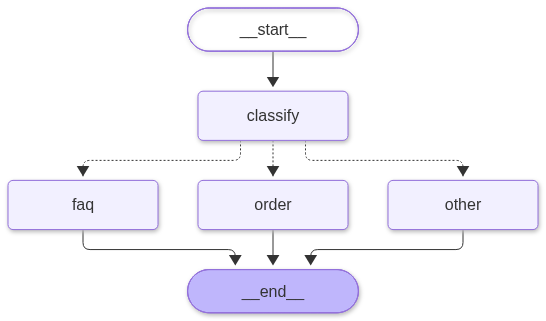

In [2]:
class BakeryState(TypedDict):
    message: str
    intent: str
    reply: str

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy or book cakes; faq = asks about prices, timings, availability or policies; other = greetings or unrelated chat"
    )

classifier = llm.with_structured_output(Intent)

FAQ_PROMPT = """You answer questions for Sweet Crumbs Home Bakery.
Use get_price for prices, is_open for timings and search_faq for policies. Never guess.
If the answer isn't found, say "I'll check with the owner." Under 50 words."""

ORDER_PROMPT = """You take cake orders for Sweet Crumbs Home Bakery.
Use get_price for totals. Before log_order, make sure you have name, item, quantity and
pickup date; ask for anything missing. After saving, read the order back. Under 60 words."""

faq_agent = create_agent(model=llm, tools=[search_faq, get_price, is_open], system_prompt=FAQ_PROMPT)
order_agent = create_agent(model=llm, tools=[get_price, log_order], system_prompt=ORDER_PROMPT)

def classify(state: BakeryState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}

def ask_agent(agent, message: str) -> str:
    result = agent.invoke({"messages": [{"role": "user", "content": message}]})
    return result["messages"][-1].content

def answer_faq(state: BakeryState) -> dict:
    return {"reply": ask_agent(faq_agent, state["message"])}

def take_order(state: BakeryState) -> dict:
    return {"reply": ask_agent(order_agent, state["message"])}

def other(state: BakeryState) -> dict:
    return {"reply": "Hello from Sweet Crumbs! I can help with cakes, prices, orders and our policies."}

def route(state: BakeryState) -> str:
    return state["intent"]

builder = StateGraph(BakeryState)
builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_node("order", take_order)
builder.add_node("other", other)

builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route, {"order": "order", "faq": "faq", "other": "other"})
builder.add_edge("faq", END)
builder.add_edge("order", END)
builder.add_edge("other", END)

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [3]:
tests = [
    "Do you deliver to my area?",
    "I'm Ravi, book 2 eggless plum cakes for 24 Dec",
    "Good morning!",
    "Is the plum cake nut-free?",
    "I want to know if you can make 2 cakes by tomorrow",
    "Bro 3 cupcakes entha?"
]

for msg in tests:
    print("\nCustomer:", msg)
    for step in graph.stream({"message": msg}, stream_mode="updates"):
        print("  ", step)


Customer: Do you deliver to my area?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'Yes, we deliver within 5\u202fkm of the bakery. Delivery costs Rs\u202f50, free for orders above Rs\u202f1,000, and requires 24\u202fhours’ notice. Pickup is available during opening hours.'}}

Customer: I'm Ravi, book 2 eggless plum cakes for 24 Dec
   {'classify': {'intent': 'order'}}
   {'order': {'reply': 'Order confirmed: 2 eggless plum cakes for Ravi, pickup 24\u202fDec. Total Rs\u202f1000. Enjoy!'}}

Customer: Good morning!
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Hello from Sweet Crumbs! I can help with cakes, prices, orders and our policies.'}}

Customer: Is the plum cake nut-free?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'Yes, the plum cake contains nuts and dried fruit. It’s not nut‑free.'}}

Customer: I want to know if you can make 2 cakes by tomorrow
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'Yes, we can make 2 cakes by tomorrow if

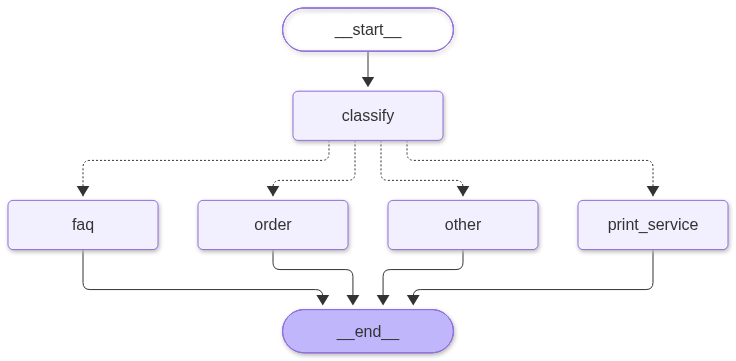

In [4]:
class StationeryState(TypedDict):
    message: str
    intent: str
    reply: str

class StationeryIntent(BaseModel):
    intent: Literal["order", "print_service", "faq", "other"] = Field(
        description="order = buying notebooks/pens/calculators; print_service = thesis binding or custom printing; faq = store hours, delivery, discounts, returns; other = greetings/unrelated"
    )

st_classifier = llm.with_structured_output(StationeryIntent)

ST_FAQS = {
    "delivery": "Free delivery within 3 km of campus for orders above Rs 500; otherwise Rs 30.",
    "returns": "Unused notebooks and pens can be exchanged within 7 days with original bill.",
    "bulk_discount": "Orders of 20+ notebooks or 10+ paper reams get a flat 10% student/faculty discount.",
    "hours": "Open Monday to Saturday 8:30 am to 9 pm, Sunday 10 am to 5 pm.",
    "custom_print": "Custom thesis binding and spiral printing take 24 hours; urgent 3-hour express costs Rs 50 extra.",
}
st_col = chroma_client.get_or_create_collection(name="brightpage_day6_faq")
st_col.upsert(ids=list(ST_FAQS.keys()), documents=list(ST_FAQS.values()))

ST_PRICES = {"a4 ream": 280, "spiral notebook": 90, "scientific calculator": 1150}
ST_ORDERS = []

@tool
def get_st_price(item: str, qty: int = 1) -> str:
    """Get price in rupees for 'a4 ream', 'spiral notebook', or 'scientific calculator'."""
    p = ST_PRICES.get(item.lower().strip())
    return f"{qty} x {item} = Rs {p * qty}" if p else f"'{item}' not found."

@tool
def log_st_order(name: str, item: str, qty: int) -> str:
    """Save a stationery order when customer name, item, and quantity are provided."""
    p = ST_PRICES.get(item.lower().strip())
    if not p:
        return "Item not in quick order list."
    total = p * qty
    ST_ORDERS.append({"name": name, "item": item, "qty": qty, "total": total})
    return f"Order saved: {qty} x {item} for {name}, Total Rs {total}."

@tool
def search_st_faq(question: str) -> str:
    """Search BrightPage Stationery policies: delivery, returns, bulk discounts, hours, custom printing."""
    res = st_col.query(query_texts=[question], n_results=3)
    return "\n".join(res["documents"][0])

st_faq_agent = create_agent(model=llm, tools=[search_st_faq, get_st_price], system_prompt="Answer BrightPage Stationery FAQs/prices from tools only. Under 50 words.")
st_order_agent = create_agent(model=llm, tools=[get_st_price, log_st_order], system_prompt="Take BrightPage Stationery orders. Ask for name, item, qty if missing. Under 50 words.")
st_print_agent = create_agent(model=llm, tools=[search_st_faq], system_prompt="Handle custom thesis/spiral printing inquiries using search_st_faq. Under 50 words.")

def st_classify(state: StationeryState) -> dict:
    return {"intent": st_classifier.invoke(state["message"]).intent}

def st_faq_node(state: StationeryState) -> dict:
    return {"reply": ask_agent(st_faq_agent, state["message"])}

def st_order_node(state: StationeryState) -> dict:
    return {"reply": ask_agent(st_order_agent, state["message"])}

def st_print_node(state: StationeryState) -> dict:
    return {"reply": ask_agent(st_print_agent, state["message"])}

def st_other_node(state: StationeryState) -> dict:
    return {"reply": "Welcome to BrightPage Stationery! Ask about notebooks, calculators, printing, or store policies."}

st_builder = StateGraph(StationeryState)
st_builder.add_node("classify", st_classify)
st_builder.add_node("faq", st_faq_node)
st_builder.add_node("order", st_order_node)
st_builder.add_node("print_service", st_print_node)
st_builder.add_node("other", st_other_node)

st_builder.add_edge(START, "classify")
st_builder.add_conditional_edges(
    "classify",
    lambda s: s["intent"],
    {"order": "order", "print_service": "print_service", "faq": "faq", "other": "other"}
)
st_builder.add_edge("faq", END)
st_builder.add_edge("order", END)
st_builder.add_edge("print_service", END)
st_builder.add_edge("other", END)

st_graph = st_builder.compile()
display(Image(st_graph.get_graph().draw_mermaid_png()))

In [5]:
st_tests = [
    "What is the bulk discount on 25 notebooks?",
    "How long does urgent thesis spiral binding take?",
    "Hi, I'm Ananya. Book 3 spiral notebooks for me.",
    "Hello there!"
]

for msg in st_tests:
    print("\nCustomer:", msg)
    for step in st_graph.stream({"message": msg}, stream_mode="updates"):
        print("  ", step)


Customer: What is the bulk discount on 25 notebooks?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'A bulk order of 25 notebooks qualifies for a flat 10\u202f% student/faculty discount.'}}

Customer: How long does urgent thesis spiral binding take?
   {'classify': {'intent': 'print_service'}}
   {'print_service': {'reply': 'Urgent thesis spiral binding is a 3‑hour express service (standard 24\u202fhrs). The express option costs an additional ₹50. All other details (hours, returns, etc.) remain unchanged.'}}

Customer: Hi, I'm Ananya. Book 3 spiral notebooks for me.
   {'classify': {'intent': 'order'}}
   {'order': {'reply': 'Your order for 3 spiral notebooks has been placed, Ananya. Total Rs\u202f270. Let me know if you need anything else!'}}

Customer: Hello there!
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Welcome to BrightPage Stationery! Ask about notebooks, calculators, printing, or store policies.'}}
